# Ten-second DPsim run with an FMI MPC-controlled grid component

This notebook builds and imports the example FMI 3.0 Model Exchange controller, connects it to a three-phase DPsim grid, simulates **10 s** at a **50 µs** EMT step, and analyzes the recorded run time and electrical response.

The opening schematic shows the exact topology used below. The grid and feeder are native DPsim components; the converter and its finite-control-set MPC are packaged in the FMU. This is a **grid-following, current-controlled converter**: it tracks a sinusoidal current reference aligned with the grid voltage, so it absorbs active power before the setpoint change and exports active power after it. The reference is synchronized to the configured 50 Hz source; this compact example has no PLL. The FMU uses a passive-positive current convention: positive current flows from the PCC into the converter.

At **5 s**, the current-reference peak changes from **+4 A to −4 A**. This reverses active-power flow and tests whether the MPC follows a large reference change, rather than only holding one operating point.


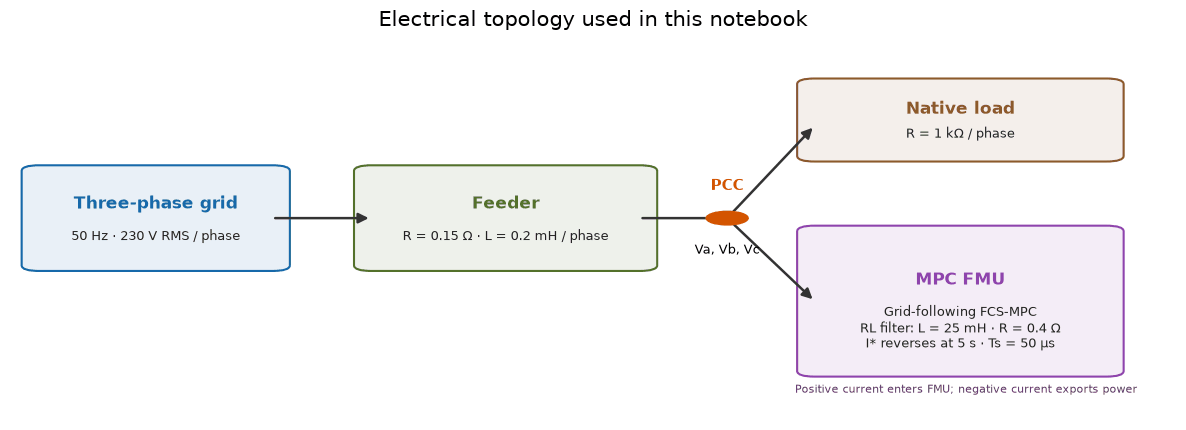

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")


def box(x, y, w, h, title, subtitle, color):
    patch = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.015",
        linewidth=1.5,
        edgecolor=color,
        facecolor=color + "18",
    )
    ax.add_patch(patch)
    ax.text(
        x + w / 2,
        y + h * 0.65,
        title,
        ha="center",
        va="center",
        fontsize=12,
        weight="bold",
        color=color,
    )
    ax.text(
        x + w / 2,
        y + h * 0.31,
        subtitle,
        ha="center",
        va="center",
        fontsize=9,
        color="#222",
    )


box(0.025, 0.41, 0.20, 0.25, "Three-phase grid", "50 Hz · 230 V RMS / phase", "#1769aa")
box(0.31, 0.41, 0.23, 0.25, "Feeder", "R = 0.15 Ω · L = 0.2 mH / phase", "#54712b")
box(0.69, 0.70, 0.25, 0.19, "Native load", "R = 1 kΩ / phase", "#8c5a2b")
box(
    0.69,
    0.13,
    0.25,
    0.37,
    "MPC FMU",
    "Grid-following FCS-MPC\nRL filter: L = 25 mH · R = 0.4 Ω\nI* reverses at 5 s · Ts = 50 µs",
    "#8e44ad",
)

# Main feeder path and PCC bus
for start, end in [
    ((0.225, 0.535), (0.31, 0.535)),
    ((0.54, 0.535), (0.615, 0.535)),
    ((0.615, 0.535), (0.69, 0.78)),
    ((0.615, 0.535), (0.69, 0.315)),
]:
    ax.add_patch(
        FancyArrowPatch(
            start, end, arrowstyle="-|>", mutation_scale=15, lw=1.8, color="#333"
        )
    )
ax.add_patch(Circle((0.615, 0.535), 0.018, color="#d35400", zorder=3))
ax.text(
    0.615,
    0.60,
    "PCC",
    ha="center",
    va="bottom",
    fontsize=11,
    weight="bold",
    color="#d35400",
)
ax.text(0.615, 0.47, "Va, Vb, Vc", ha="center", va="top", fontsize=9)
ax.text(
    0.82,
    0.08,
    "Positive current enters FMU; negative current exports power",
    ha="center",
    va="center",
    fontsize=8,
    color="#5e3370",
)
ax.set_title("Electrical topology used in this notebook", fontsize=15, pad=12)
fig.tight_layout()
plt.show()

## Model, MPC objective, and setpoint event

The network contains a balanced 50 Hz voltage source, a series R-L feeder, a native 1 kΩ-per-phase load, and the imported controller FMU connected in parallel at the PCC. The FMU represents an averaged two-level converter and its output filter. Its current reference is synchronized to the configured 50 Hz source phase, giving simplified **grid-following** behavior; this example has no PLL. With the passive-positive terminal convention, positive in-phase current means the converter consumes active power; negative in-phase current means it exports power to the grid.

At each 50 µs sample, the finite-control-set MPC evaluates the eight three-phase bridge switching vectors, with each leg voltage in `{−350 V, +350 V}`. It predicts the next filter current using

\[
 i_{k+1}^{pred}=i_k + \frac{T_s}{L_f}(v_{PCC,k}-u_{inv,k}-R_f i_k),
\]

and minimizes the three-phase predicted-current tracking error plus a small penalty for switching leg states. The balanced sinusoidal reference is 50 Hz. Its peak changes synchronously with the 50 µs controller schedule at **5 s**, from **+4 A to −4 A**. The reference therefore reverses sign while retaining its grid-synchronous phase, exercising active-power reversal through the same FMU and network interface.

The FMI model exposes PCC voltages as continuous inputs, converter terminal currents as continuous outputs, and scheduled events every 50 µs. Its state snapshot functions enable DPsim's rollback/Newton coupling.

This is a feasibility model for FMI import and event scheduling. It omits DC-link dynamics, PWM dead time, losses, protection, and a production-grade optimizer. The current step tests reference tracking in this simplified averaged model; it is not a validated transient specification for a physical converter.


## Run the 10-second case

The simulation advances **200,000 network steps**. To keep memory and notebook size modest, the result logger records every tenth step (0.5 ms). The controller still updates and DPsim still solves the network at every 50 µs step. The 5 s setpoint reversal lands exactly on a controller/network event. The notebook records wall time and peak memory for the DPsim process separately from simulated duration.


In [2]:
import json
import subprocess
import time
from pathlib import Path

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "dpsim-fmi/CMakeLists.txt").is_file()
)
BUILD = ROOT / "build-fmi"
FMU_BUILDER = ROOT / "dpsim-fmi/examples/mpc_grid/build_fmu.sh"
FMU = BUILD / "mpc-grid-fmu/mpc_grid_mpc.fmu"
RUNNER = BUILD / "dpsim-fmi/FMI_EMT_Ph3_Mixed"
CASE = BUILD / "mpc-grid-10s"
CASE.mkdir(parents=True, exist_ok=True)

# Build from the checked-in C source so the notebook does not depend on a stale FMU.
build_result = subprocess.run(
    ["bash", str(FMU_BUILDER)], cwd=ROOT, text=True, capture_output=True, check=True
)
print(build_result.stdout.strip())

config = json.loads((ROOT / "dpsim-fmi/examples/mpc_grid/config.json").read_text())
config["stop_time_s"] = 10.0
config["log_downsampling"] = 10
config_path = CASE / "config_10s.json"
config_path.write_text(json.dumps(config, indent=2) + "\n")

# GNU time reports the runner's own peak RSS and wall time on this Linux example.
time_file = CASE / "process_time.txt"
command = [
    "/usr/bin/time",
    "-f",
    "wall_seconds=%e\nmax_rss_kib=%M",
    "-o",
    str(time_file),
    str(RUNNER),
    str(FMU),
    str(config_path),
    "10.0",
    "0.00005",
]
start = time.perf_counter()
run = subprocess.run(command, cwd=CASE, text=True, capture_output=True, check=True)
notebook_wall_s = time.perf_counter() - start
print(run.stdout.strip())
print(run.stderr.strip())
print(f"Notebook-measured process wall time: {notebook_wall_s:.3f} s")

# Parse the separate process resource report.
resource_report = {}
for item in time_file.read_text().split():
    key, value = item.split("=", 1)
    resource_report[key] = float(value)
print("Runner resource report:", resource_report)

Built /home/matthiasmees/dpsim/build-fmi/mpc-grid-fmu/mpc_grid_mpc.fmu


Mixed native EMT ABC / FMI completed: 3 FMU states, 200000 steps
[19:07:32.117876 MnaSolverFactory info] creating KLUAdapter solver implementation
Notebook-measured process wall time: 10.217 s
Runner resource report: {'wall_seconds': 10.21, 'max_rss_kib': 15072.0}


## Runtime, tracking, and power-flow metrics

The full-run log is decimated to 2 kHz, but the counters and simulation end time cover the complete 10-second trajectory. Tracking metrics use logged samples after the first 100 ms, excluding initialization. Separate pre-step and post-step windows quantify settled tracking and mean active power on each side of the reversal; a short transition window reports the transient tracking error.


In [3]:
import numpy as np
import pandas as pd
from IPython.display import display

log_path = CASE / "logs/fmi_mixed.csv"
data = pd.read_csv(log_path, skipinitialspace=True)
data.columns = data.columns.str.strip()
time_s = data["time"].to_numpy()
phase_current = data[[f"i_{p}" for p in "abc"]].to_numpy(dtype=float)
phase_reference = data[[f"i_ref_{p}" for p in "abc"]].to_numpy(dtype=float)
phase_voltage = data[[f"pcc_voltage_{k}" for k in range(3)]].to_numpy(dtype=float)
error = phase_current - phase_reference
line_current = data[[f"line_current_{k}" for k in range(3)]].to_numpy(dtype=float)
load_current = data[[f"load_current_{k}" for k in range(3)]].to_numpy(dtype=float)
fmu_current = data[[f"converter_current_{k}" for k in range(3)]].to_numpy(dtype=float)
kcl = line_current + load_current + fmu_current
mask = time_s >= 0.1
pre_step = (time_s >= 4.0) & (time_s < 4.9)
transition = (time_s >= 5.0) & (time_s < 5.2)
post_step = (time_s >= 5.5) & (time_s <= 10.0)
step_s = 50e-6
simulated_s = float(config["stop_time_s"])
logged_last_time_s = float(time_s[-1])
network_steps = round(simulated_s / step_s)
wall_s = resource_report["wall_seconds"]
metrics = {
    "simulated_duration_s": simulated_s,
    "last_logged_time_s": logged_last_time_s,
    "network_step_s": step_s,
    "network_steps": int(network_steps),
    "logged_samples": int(len(data)),
    "log_interval_s": float(np.median(np.diff(time_s))),
    "controller_updates_expected_at_stop": int(network_steps + 1),
    "controller_ticks_at_last_logged_sample": int(data.controller_ticks.iloc[-1]),
    "DPsim_wall_time_s": wall_s,
    "simulated_seconds_per_wall_second": simulated_s / wall_s,
    "network_steps_per_wall_second": network_steps / wall_s,
    "DPsim_peak_RSS_MiB": resource_report["max_rss_kib"] / 1024,
    "current_tracking_RMS_error_after_100ms_A": float(
        np.sqrt(np.mean(error[mask] ** 2))
    ),
    "current_tracking_max_error_after_100ms_A": float(np.max(np.abs(error[mask]))),
    "PCC_KCL_max_residual_after_100ms_A": float(np.max(np.abs(kcl[mask]))),
    "mean_converter_active_power_after_100ms_W": float(
        np.mean(np.sum(phase_voltage[mask] * phase_current[mask], axis=1))
    ),
    "pre_step_current_tracking_RMS_error_A_4.0_to_4.9s": float(
        np.sqrt(np.mean(error[pre_step] ** 2))
    ),
    "transition_current_tracking_RMS_error_A_5.0_to_5.2s": float(
        np.sqrt(np.mean(error[transition] ** 2))
    ),
    "post_step_current_tracking_RMS_error_A_5.5_to_10s": float(
        np.sqrt(np.mean(error[post_step] ** 2))
    ),
    "pre_step_mean_active_power_W_4.0_to_4.9s": float(
        np.mean(np.sum(phase_voltage[pre_step] * phase_current[pre_step], axis=1))
    ),
    "post_step_mean_active_power_W_5.5_to_10s": float(
        np.mean(np.sum(phase_voltage[post_step] * phase_current[post_step], axis=1))
    ),
    "max_logged_Newton_iterations": int(data.newton_iterations.max()),
    "max_logged_Newton_residual": float(data.newton_residual.max()),
    "max_logged_coupling_error_A": float(data.fmi_coupling_error_A.max()),
    "FMI_evaluation_requests_at_last_logged_sample": int(
        data.fmi_evaluation_requests.iloc[-1]
    ),
}
metrics_frame = pd.DataFrame([metrics]).T.rename(columns={0: "value"})
display(metrics_frame)
(CASE / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")

,value
simulated_duration_s,1.000000e+01
last_logged_time_s,9.999550e+00
network_step_s,5.000000e-05
network_steps,2.000000e+05
logged_samples,2.000100e+04
log_interval_s,5.000000e-04
controller_updates_expected_at_stop,2.000010e+05
controller_ticks_at_last_logged_sample,1.999920e+05
DPsim_wall_time_s,1.021000e+01
simulated_seconds_per_wall_second,9.794319e-01


1262

## Result plots

The first result view zooms into the first grid cycle. The full-run plots show the 20 ms moving RMS tracking error, mean active power, controller updates, and FMI evaluation workload across 10 s. A dedicated zoom around 5 s overlays phase-a reference and measured current with active power, so the setpoint and direction reversal are visible directly.


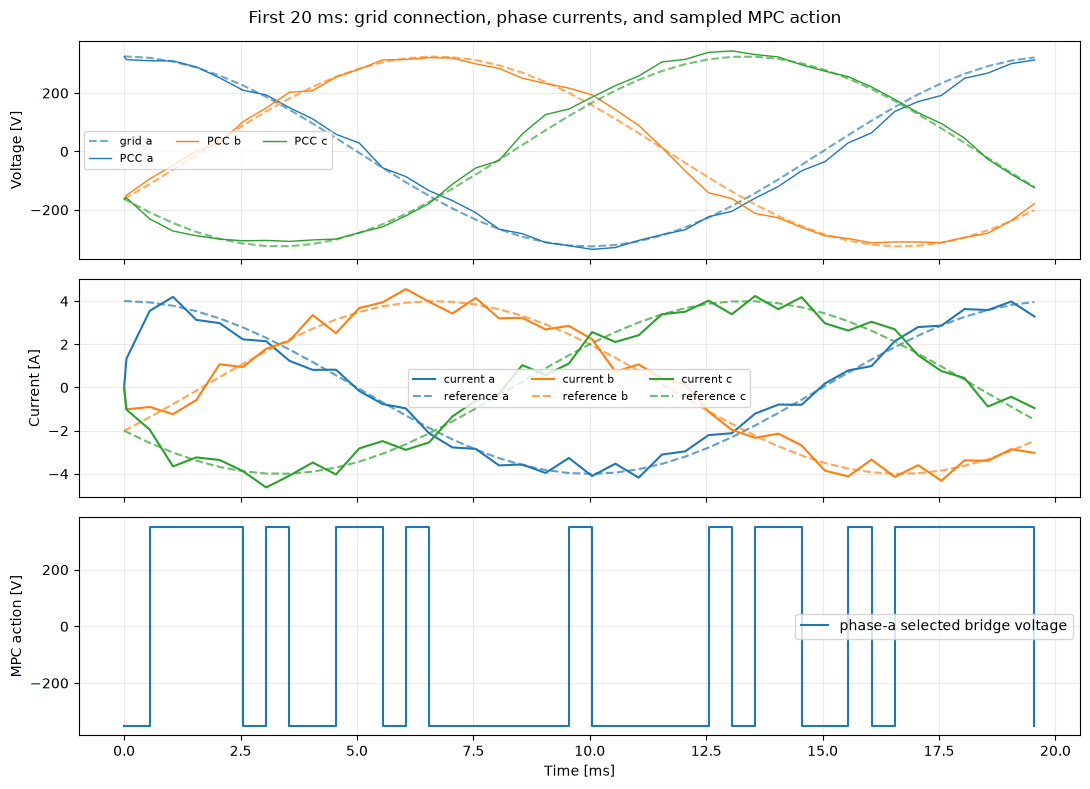

In [4]:
# First cycle: three-phase PCC/grid voltage and MPC current tracking.
cycle = time_s <= 0.02 + 1e-12
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for k, phase in enumerate("abc"):
    axes[0].plot(
        time_s[cycle] * 1e3,
        data.loc[cycle, f"grid_voltage_{k}"],
        ls="--",
        alpha=0.65,
        label=f"grid {phase}" if k == 0 else None,
        color=f"C{k}",
    )
    axes[0].plot(
        time_s[cycle] * 1e3,
        data.loc[cycle, f"pcc_voltage_{k}"],
        lw=1,
        label=f"PCC {phase}",
        color=f"C{k}",
    )
    axes[1].plot(
        time_s[cycle] * 1e3,
        phase_current[cycle, k],
        label=f"current {phase}",
        color=f"C{k}",
    )
    axes[1].plot(
        time_s[cycle] * 1e3,
        phase_reference[cycle, k],
        ls="--",
        alpha=0.7,
        label=f"reference {phase}",
        color=f"C{k}",
    )
axes[0].set_ylabel("Voltage [V]")
axes[0].legend(ncol=3, fontsize=8)
axes[1].set_ylabel("Current [A]")
axes[1].legend(ncol=3, fontsize=8)
axes[2].step(
    time_s[cycle] * 1e3,
    data.loc[cycle, "u_inv_a"],
    where="post",
    color="C0",
    label="phase-a selected bridge voltage",
)
axes[2].set_ylabel("MPC action [V]")
axes[2].set_xlabel("Time [ms]")
axes[2].legend()
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("First 20 ms: grid connection, phase currents, and sampled MPC action")
fig.tight_layout()
plt.show()

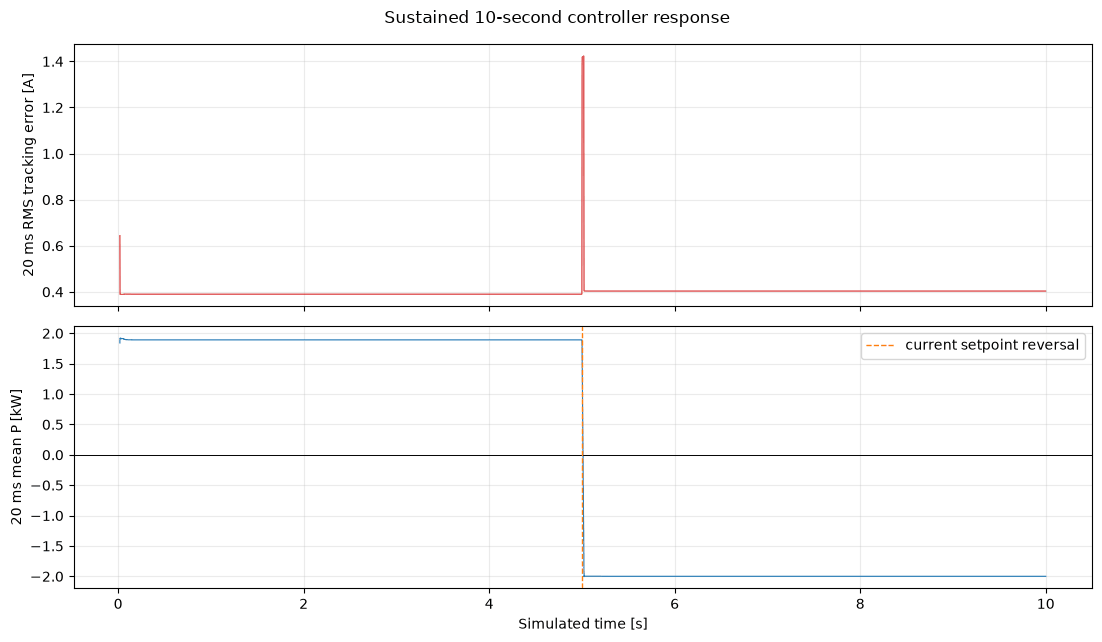

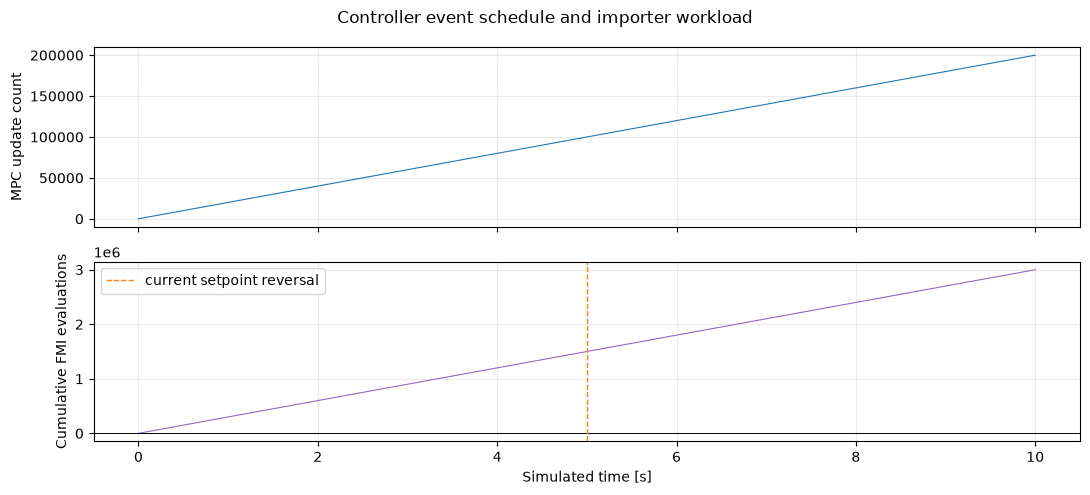

In [5]:
# Full run: 20 ms moving RMS current error and mean active power.
logged_dt = float(np.median(np.diff(time_s)))
window = max(1, round(0.02 / logged_dt))
error_rms = (
    pd.DataFrame(error)
    .pow(2)
    .rolling(window, min_periods=window)
    .mean()
    .mean(axis=1)
    .pow(0.5)
)
instantaneous_power = (phase_voltage * phase_current).sum(axis=1)
power_mean = pd.Series(instantaneous_power).rolling(window, min_periods=window).mean()
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(time_s, error_rms, color="tab:red", lw=0.8)
axes[0].set_ylabel("20 ms RMS tracking error [A]")
axes[1].plot(time_s, power_mean / 1e3, color="tab:blue", lw=0.8)
axes[1].set_ylabel("20 ms mean P [kW]")
axes[1].axhline(0, color="black", lw=0.7)
axes[1].axvline(
    5.0, color="tab:orange", ls="--", lw=1, label="current setpoint reversal"
)
axes[1].legend()
axes[1].set_xlabel("Simulated time [s]")
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("Sustained 10-second controller response")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].step(time_s, data.controller_ticks, where="post", lw=0.8)
axes[0].set_ylabel("MPC update count")
axes[1].plot(time_s, data.fmi_evaluation_requests, lw=0.8, color="tab:purple")
axes[1].set_ylabel("Cumulative FMI evaluations")
axes[1].axhline(0, color="black", lw=0.7)
axes[1].axvline(
    5.0, color="tab:orange", ls="--", lw=1, label="current setpoint reversal"
)
axes[1].legend()
axes[1].set_xlabel("Simulated time [s]")
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("Controller event schedule and importer workload")
fig.tight_layout()
plt.show()

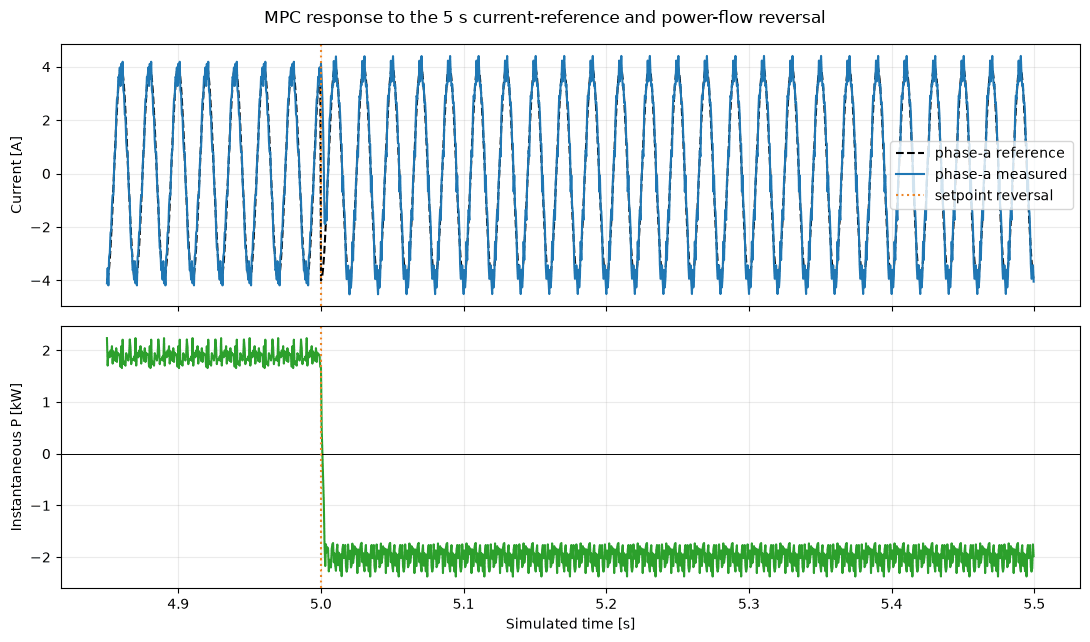

In [6]:
step_view = (time_s >= 4.85) & (time_s <= 5.50)
active_power = np.sum(phase_voltage * phase_current, axis=1)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(
    time_s[step_view],
    phase_reference[step_view, 0],
    "--",
    label="phase-a reference",
    color="black",
)
axes[0].plot(
    time_s[step_view],
    phase_current[step_view, 0],
    label="phase-a measured",
    color="tab:blue",
)
axes[0].axvline(5.0, color="tab:orange", ls=":", label="setpoint reversal")
axes[0].set_ylabel("Current [A]")
axes[0].legend()
axes[1].plot(time_s[step_view], active_power[step_view] / 1e3, color="tab:green")
axes[1].axhline(0, color="black", lw=0.7)
axes[1].axvline(5.0, color="tab:orange", ls=":")
axes[1].set_ylabel("Instantaneous P [kW]")
axes[1].set_xlabel("Simulated time [s]")
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("MPC response to the 5 s current-reference and power-flow reversal")
fig.tight_layout()
plt.show()

## Interpretation and limits

The 5 s event changes the grid-following current command from absorbing to exporting active power. Compare the phase-a reference and measured-current traces around the step, then check the pre-step and post-step tracking and mean-power metrics above. A successful run demonstrates that this FMU's MPC responds to a substantial reference reversal while integrated with the DPsim EMT network; it does not establish industrial control performance.

The model source, FMU build script, configuration, and command-line reproduction are in `dpsim-fmi/examples/mpc_grid/`. The generated FMU, CSV, metrics, and figures are kept under `build-fmi/mpc-grid-10s/`.
